## Association Between Individual Characteristics and Medical Costs: A Multiple Linear Regression Analysis

**Disciplina:** ACH2036 - Métodos Quantitativos para Análise Multivariada
**Autor:** Aaron Ferraz do Amaral Martins da Silva
**Número USP:** 14554474

### 1. Problema de regressão a ser tratado
A base Medical Cost Personal Datasets, disponibilizada por Miri Choi no
Kaggle, contém 1.338 registros de custos médicos individuais e características
dos beneficiários.
O arquivo utilizado é insurance.csv. Os custos são expressos em dólares americanos.
A análise se limita à base disponibilizada; não se presume representatividade
populacional nem se atribui ao arquivo uma origem clínica independentemente verificada.

O objetivo é avaliar a associação entre custos médicos e idade, sexo, índice de
massa corporal (IMC), número de dependentes, tabagismo e região, por regressão
linear múltipla. O estudo é observacional e não permite inferir causalidade.
A escolha atende aos critérios: resposta monetária contínua (charges), seis
preditoras e três variáveis categóricas. Valores monetários continuam sendo tratados
como contínuos estatisticamente, embora sejam registrados com precisão finita.

Fonte: Choi, M. Medical Cost Personal Datasets. Kaggle.
https://www.kaggle.com/datasets/mirichoi0218/insurance

### 2. Descrição da base
Cada linha representa um registro individual. O bloco lê o CSV, confere tipos,
ausências, categorias e repetições. Nenhuma coluna é um identificador a excluir.
O caminho relativo permite executar o trabalho em outro computador.

In [2]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import scipy
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})

caminho = Path("Dataset") / "insurance.csv"
if not caminho.exists():
    raise FileNotFoundError("Coloque insurance.csv na subpasta Dataset, ao lado do notebook.")

dados = pd.read_csv(caminho)
esperadas = {"age", "sex", "bmi", "children", "smoker", "region", "charges"}
assert set(dados.columns) == esperadas, "Colunas diferentes das esperadas."

display(pd.DataFrame({
    "tipo_armazenado": dados.dtypes.astype(str),
    "ausentes": dados.isna().sum(),
    "valores_distintos": dados.nunique()
}))
print(f"Dimensões: {dados.shape[0]} registros e {dados.shape[1]} colunas.")
print(f"Linhas integralmente repetidas: {dados.duplicated().sum()}.")
display(dados.head())

,tipo_armazenado,ausentes,valores_distintos
age,int64,0,47
sex,str,0,2
bmi,float64,0,548
children,int64,0,6
smoker,str,0,2
region,str,0,4
charges,float64,0,1337


Dimensões: 1338 registros e 7 colunas.
Linhas integralmente repetidas: 1.


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Resultado e decisão. Há 1.338 registros, sete colunas e nenhuma ausência.
Uma linha é integralmente repetida. Como não há identificador que permita
determinar se representa a mesma pessoa ou pessoas diferentes com os mesmos
atributos registrados, ela foi preservada; igualdade de valores não comprova
duplicidade de indivíduo. Essa incerteza é uma limitação. Não há exclusão
automática de valores extremos, que podem representar custos elevados reais.

#### Dicionário de variáveis
Os nomes originais são curtos e foram mantidos no código. Os gráficos usam
rótulos descritivos.

| Nome original | Descrição | Natureza estatística | Papel |
|---|---|---|---|
| `charges` | Custo médico individual faturado ao seguro, em US$ | Contínua | Resposta original |
| `age` | Idade do beneficiário, registrada em anos completos | Inteira | Preditora |
| `sex` | Sexo informado: feminino ou masculino | Categórica não ordinal | Preditora |
| `bmi` | Índice de massa corporal, em kg/m² | Contínua | Preditora |
| `children` | Número de filhos/dependentes cobertos, conforme descrição da base | Inteira | Preditora |
| `smoker` | Tabagismo informado: não ou sim | Categórica não ordinal | Preditora |
| `region` | Região nos EUA: nordeste, noroeste, sudeste ou sudoeste | Categórica não ordinal | Preditora |
| `log_charges` | Logaritmo natural de `charges` | Contínua | Resposta após transformação |

#### Tratamento das categorias
O bloco traduz os rótulos e declara explicitamente as variáveis categóricas.
Não há agrupamento de categorias: suas frequências e significados não o
justificam. A primeira categoria de cada lista será a referência na regressão.

In [3]:
base = dados.copy()
mapas = {
    "sex": {"female": "Feminino", "male": "Masculino"},
    "smoker": {"no": "Não", "yes": "Sim"},
    "region": {
        "northeast": "Nordeste", "northwest": "Noroeste",
        "southeast": "Sudeste", "southwest": "Sudoeste"
    }
}
for coluna, mapa in mapas.items():
    assert base[coluna].isin(mapa).all(), f"Categoria desconhecida em {coluna}."
    base[coluna] = pd.Categorical(
        base[coluna].map(mapa), categories=list(mapa.values())
    )

assert not base.isna().any().any()
assert (base["charges"] > 0).all(), "Log e Box-Cox exigem custos positivos."
assert (base[["age", "bmi", "children"]] >= 0).all().all()

categoricas = ["sex", "smoker", "region"]
numericas = ["age", "bmi", "children"]
rotulos = {
    "age": "Idade (anos)", "bmi": "IMC (kg/m²)",
    "children": "Dependentes", "charges": "Custo médico (US$)",
    "log_charges": "Logaritmo do custo"
}
for coluna in categoricas:
    frequencias = base[coluna].value_counts(sort=False).rename("n").to_frame()
    frequencias["percentual"] = 100 * frequencias["n"] / len(base)
    print(f"{coluna} | referência: {base[coluna].cat.categories[0]}")
    display(frequencias.round(2))

sex | referência: Feminino


,n,percentual
sex,,
Feminino,662,49.48
Masculino,676,50.52


smoker | referência: Não


,n,percentual
smoker,,
Não,1064,79.52
Sim,274,20.48


region | referência: Nordeste


,n,percentual
region,,
Nordeste,324,24.22
Noroeste,325,24.29
Sudeste,364,27.20
Sudoeste,325,24.29


Resultado. As categorias de sexo e região são relativamente equilibradas.
Há 274 fumantes (20,48%) e 1.064 não fumantes (79,52%); a categoria menor tem
quantidade suficiente para ser mantida. Todas as seis preditoras permanecem
candidatas à seleção.

#### Assimetria e transformação da resposta
Investiguei a família Box-Cox para a
resposta positiva. stats.boxcox estima o expoente por máxima verossimilhança
marginal, sem considerar as preditoras. Usamos esse resultado como orientação
exploratória, não como garantia de normalidade dos erros do modelo.

Quando o expoente é próximo de zero, o logaritmo natural é uma alternativa
simples e interpretável. Não se aplica Box-Cox aos dependentes, que incluem
zero e são uma contagem; assimetria de preditoras não exige transformação
automática. Não há variável proporcional que motive a transformação logito.

In [4]:
_, lambda_bc = stats.boxcox(base["charges"])
base["log_charges"] = np.log(base["charges"])

assimetria = base[numericas + ["charges", "log_charges"]].skew()
display(assimetria.rename("assimetria").to_frame().round(3))
display(Markdown(
    f"O expoente Box-Cox estimado foi **λ = {lambda_bc:.4f}**. "
    f"A assimetria passou de **{assimetria['charges']:.3f}** na escala "
    f"original para **{assimetria['log_charges']:.3f}** na escala logarítmica. "
    "Adotamos **log_charges** como resposta pela proximidade de λ a zero, "
    "pela redução da assimetria marginal e pela interpretação multiplicativa. "
    "A adequação dos erros será avaliada separadamente na seção 5."
))

,assimetria
age,0.056
bmi,0.284
children,0.938
charges,1.516
log_charges,-0.090


O expoente Box-Cox estimado foi **λ = 0.0436**. A assimetria passou de **1.516** na escala original para **-0.090** na escala logarítmica. Adotamos **log_charges** como resposta pela proximidade de λ a zero, pela redução da assimetria marginal e pela interpretação multiplicativa. A adequação dos erros será avaliada separadamente na seção 5.

### 3. Caracterização das principais variáveis após eventuais tratamentos
#### Distribuições individuais
As estatísticas, histogramas e boxplots caracterizam a resposta transformada
e as três preditoras numéricas. A resposta original é mantida apenas para
documentar o efeito da transformação. Os dados não foram padronizados:
idade, IMC e dependentes preservam suas unidades para interpretação.

,count,mean,std,min,25%,50%,75%,max,assimetria
age,1338.0,39.207,14.050,18.000,27.000,39.000,51.000,64.000,0.056
bmi,1338.0,30.663,6.098,15.960,26.296,30.400,34.694,53.130,0.284
children,1338.0,1.095,1.205,0.000,0.000,1.000,2.000,5.000,0.938
charges,1338.0,13270.422,12110.011,1121.874,4740.287,9382.033,16639.913,63770.428,1.516
log_charges,1338.0,9.099,0.920,7.023,8.464,9.147,9.720,11.063,-0.090


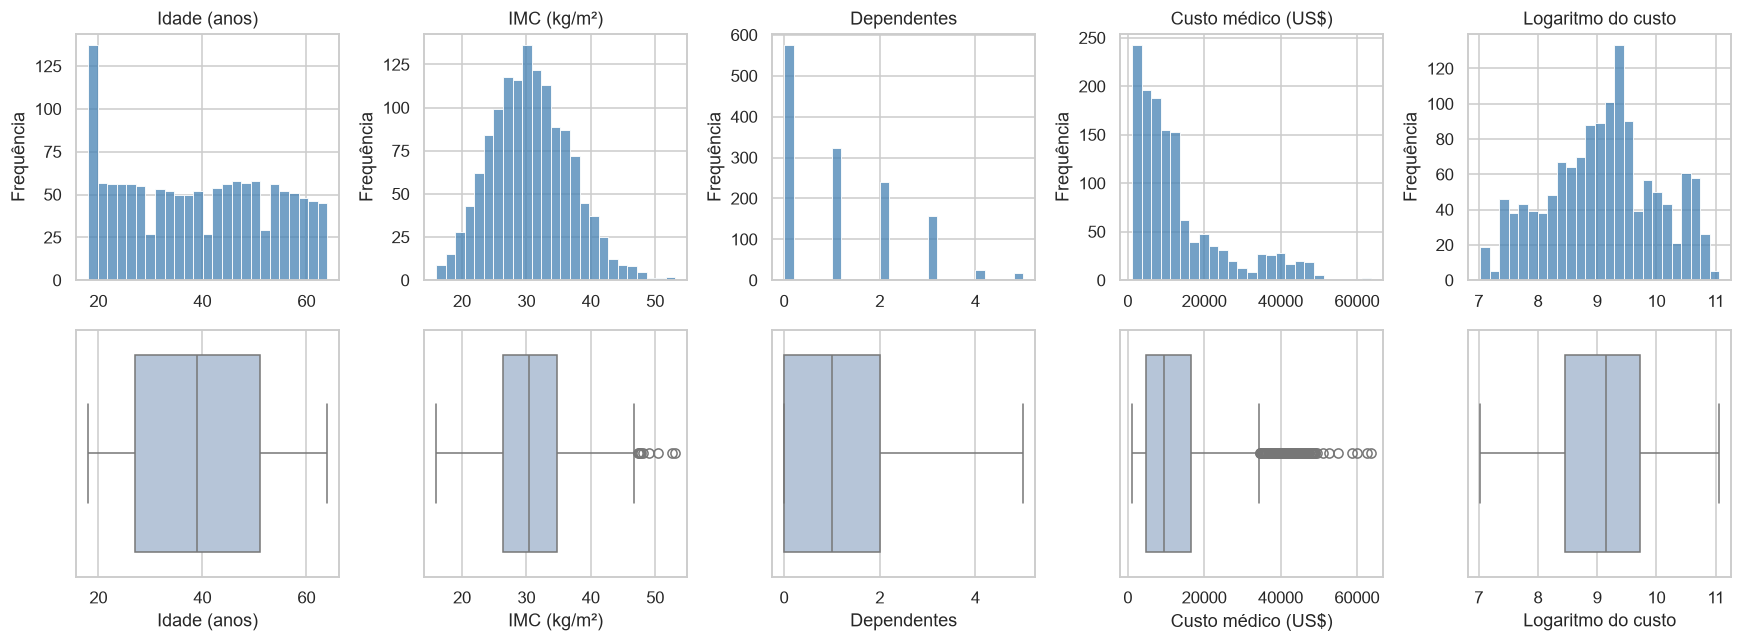

In [5]:
quantitativas = numericas + ["charges", "log_charges"]
resumo = base[quantitativas].describe().T
resumo["assimetria"] = base[quantitativas].skew()
display(resumo.round(3))

fig, eixos = plt.subplots(2, 5, figsize=(16, 6))
for i, coluna in enumerate(quantitativas):
    sns.histplot(base[coluna], bins=25, ax=eixos[0, i], color="steelblue")
    eixos[0, i].set_title(rotulos[coluna])
    eixos[0, i].set_xlabel("")
    eixos[0, i].set_ylabel("Frequência")
    sns.boxplot(x=base[coluna], ax=eixos[1, i], color="lightsteelblue")
    eixos[1, i].set_xlabel(rotulos[coluna])
plt.tight_layout()
plt.show()

Discussão. O custo médio é de US$ 13.270,42, acima da mediana de
US$ 9.382,03, consistente com a cauda à direita. Os custos variam de
US$ 1.121,87 a US$ 63.770,43. A escala logarítmica reduz a assimetria e a
influência visual dos custos mais elevados. Isso não comprova normalidade
condicional. As idades vão de 18 a 64 anos, o IMC de 15,96 a 53,13 e os
dependentes de zero a cinco. Não foram excluídas observações com base
apenas nos limites dos boxplots.

#### Associações entre variáveis numéricas
A matriz de dispersão apresenta distribuições na diagonal e relações entre
pares fora dela, seguindo a sugestão de scatterplot matrix do enunciado.
Usamos pairplot por ser uma implementação disponível localmente. A correlação de Pearson resume
apenas a componente linear e não orienta exclusões isoladamente.

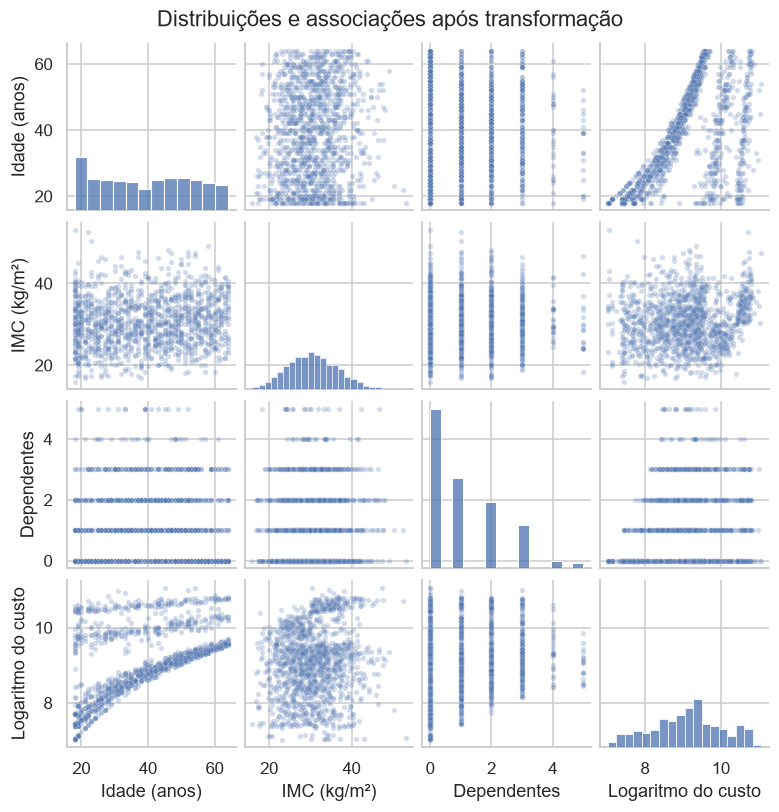

,age,bmi,children,log_charges
age,1.000,0.109,0.042,0.528
bmi,0.109,1.000,0.013,0.133
children,0.042,0.013,1.000,0.161
log_charges,0.528,0.133,0.161,1.000


In [6]:
g = sns.pairplot(
    base[numericas + ["log_charges"]],
    diag_kind="hist", height=1.8,
    plot_kws={"alpha": 0.25, "s": 12}
)
for i, coluna in enumerate(numericas + ["log_charges"]):
    g.axes[-1, i].set_xlabel(rotulos[coluna])
    g.axes[i, 0].set_ylabel(rotulos[coluna])
g.figure.suptitle("Distribuições e associações após transformação", y=1.02)
plt.show()

correlacoes = base[numericas + ["log_charges"]].corr()
display(correlacoes.round(3))

In [7]:
corr_y = correlacoes["log_charges"].drop("log_charges")
display(Markdown(
    "**Discussão.** As correlações lineares com o logaritmo do custo são: "
    + "; ".join(f"{rotulos[v]}: **{r:.3f}**" for v, r in corr_y.items())
    + ". A relação entre idade e log-custo apresenta faixas distintas e "
    "curvatura, indicando heterogeneidade não explicada por uma única "
    "preditora. Relações marginais não representam os coeficientes "
    "condicionais do modelo múltiplo nem demonstram causalidade."
))

**Discussão.** As correlações lineares com o logaritmo do custo são: Idade (anos): **0.528**; IMC (kg/m²): **0.133**; Dependentes: **0.161**. A relação entre idade e log-custo apresenta faixas distintas e curvatura, indicando heterogeneidade não explicada por uma única preditora. Relações marginais não representam os coeficientes condicionais do modelo múltiplo nem demonstram causalidade.

#### Associações com as categorias
Comparamos o custo original por meio de tabelas e o logaritmo do custo por
boxplots. A contagem de cada grupo permite avaliar a sustentação amostral
das comparações. Não são realizados testes separados para escolher variáveis:
a seleção ocorrerá de forma conjunta na seção 4.

Custos por sex:


,n,media,mediana,desvio_padrao
sex,,,,
Feminino,662,12569.58,9412.96,11128.70
Masculino,676,13956.75,9369.62,12971.03


Custos por smoker:


,n,media,mediana,desvio_padrao
smoker,,,,
Não,1064,8434.27,7345.41,5993.78
Sim,274,32050.23,34456.35,11541.55


Custos por region:


,n,media,mediana,desvio_padrao
region,,,,
Nordeste,324,13406.38,10057.65,11255.80
Noroeste,325,12417.58,8965.80,11072.28
Sudeste,364,14735.41,9294.13,13971.10
Sudoeste,325,12346.94,8798.59,11557.18


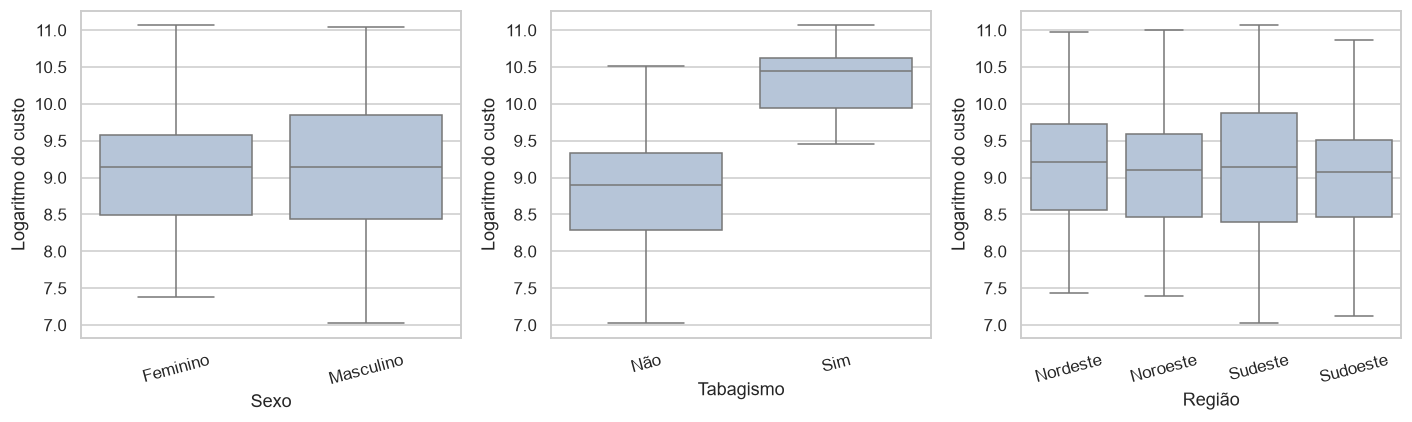

In [8]:
for coluna in categoricas:
    print(f"Custos por {coluna}:")
    display(base.groupby(coluna, observed=True)["charges"].agg(
        n="count", media="mean", mediana="median", desvio_padrao="std"
    ).round(2))

fig, eixos = plt.subplots(1, 3, figsize=(13, 4))
for eixo, coluna in zip(eixos, categoricas):
    sns.boxplot(data=base, x=coluna, y="log_charges", ax=eixo,
                color="lightsteelblue")
    eixo.set_xlabel({"sex": "Sexo", "smoker": "Tabagismo", "region": "Região"}[coluna])
    eixo.set_ylabel("Logaritmo do custo")
    eixo.tick_params(axis="x", labelrotation=15)
plt.tight_layout()
plt.show()

In [9]:
medias_fumo = base.groupby("smoker", observed=True)["charges"].mean()
display(Markdown(
    f"**Discussão.** Fumantes apresentam custo médio de "
    f"**US$ {medias_fumo['Sim']:,.2f}**, contra "
    f"**US$ {medias_fumo['Não']:,.2f}** entre não fumantes. "
    "O boxplot também evidencia separação das distribuições na escala "
    "logarítmica. Essa comparação é descritiva: diferenças de composição "
    "entre grupos podem contribuir para o resultado. Sexo e região apresentam "
    "maior sobreposição; isso não justifica exclusão antes da seleção conjunta."
))

**Discussão.** Fumantes apresentam custo médio de **US$ 32,050.23**, contra **US$ 8,434.27** entre não fumantes. O boxplot também evidencia separação das distribuições na escala logarítmica. Essa comparação é descritiva: diferenças de composição entre grupos podem contribuir para o resultado. Sexo e região apresentam maior sobreposição; isso não justifica exclusão antes da seleção conjunta.

### 4. Seleção de variáveis
#### Procedimento stepwise
Adotamos stepwise bidirecional por AIC, em conformidade com a sugestão
de seleção automatizada simples do enunciado. O algoritmo começa com intercepto
e avalia, a cada rodada, a inclusão ou exclusão de um termo inteiro.
Aceita a mudança com menor AIC somente se ela reduzir o AIC atual e encerra
quando nenhuma mudança individual melhora o critério. Assim, uma categórica
entra ou sai com todos os seus indicadores, evitando selecionar categorias
isoladamente.

O AIC penaliza a quantidade de parâmetros: valores menores são preferíveis
entre modelos da mesma resposta, nas mesmas observações. O procedimento
é exploratório, não garante o melhor subconjunto global e não garante as
premissas LINE. O mínimo de cinco preditoras refere-se à base candidata;
não se força sua permanência no modelo selecionado.

O código separa o ajuste de uma fórmula e a busca stepwise. C(...) indica
tratamento categórico; o intercepto é incluído automaticamente. Os modelos
usam a mesma amostra, e missing='raise' impede exclusões silenciosas.

In [10]:
termos_candidatos = [
    "age", "bmi", "children", "C(sex)", "C(smoker)", "C(region)"
]

def ajustar(termos, resposta="log_charges"):
    formula = resposta + " ~ " + (" + ".join(termos) if termos else "1")
    return smf.ols(formula, data=base, missing="raise").fit()

def stepwise_aic(candidatos):
    selecionados = []
    modelo_atual = ajustar(selecionados)
    historico = [{"etapa": 0, "mudanca": "Intercepto", "AIC": modelo_atual.aic}]

    while True:
        alternativas = []
        # Inclusões dos termos ainda ausentes.
        for termo in candidatos:
            if termo not in selecionados:
                novos = selecionados + [termo]
                teste = ajustar(novos)
                alternativas.append((teste.aic, "Incluir " + termo, novos, teste))
        # Exclusões dos termos presentes, preservando blocos categóricos.
        for termo in selecionados:
            novos = [t for t in selecionados if t != termo]
            teste = ajustar(novos)
            alternativas.append((teste.aic, "Excluir " + termo, novos, teste))

        melhor = min(alternativas, key=lambda item: item[0])
        if melhor[0] >= modelo_atual.aic - 1e-8:
            break
        _, mudanca, selecionados, modelo_atual = melhor
        historico.append({
            "etapa": len(historico), "mudanca": mudanca, "AIC": modelo_atual.aic
        })

    return modelo_atual, selecionados, pd.DataFrame(historico)

modelo, termos_selecionados, historico = stepwise_aic(termos_candidatos)
modelo_completo = ajustar(termos_candidatos)
display(historico.round(3))
print("Fórmula selecionada:", modelo.model.formula)

,etapa,mudanca,AIC
0,0,Intercepto,3573.574
1,1,Incluir C(smoker),2792.835
2,2,Incluir age,1777.521
3,3,Incluir children,1685.252
4,4,Incluir bmi,1660.015
5,5,Incluir C(region),1642.616
6,6,Incluir C(sex),1635.033


Fórmula selecionada: log_charges ~ C(smoker) + age + children + bmi + C(region) + C(sex)


In [11]:
comparacao = pd.DataFrame({
    "modelo": ["Intercepto", "Completo", "Stepwise"],
    "AIC": [ajustar([]).aic, modelo_completo.aic, modelo.aic],
    "n": [ajustar([]).nobs, modelo_completo.nobs, modelo.nobs],
    "coeficientes_com_intercepto": [
        len(ajustar([]).params), len(modelo_completo.params), len(modelo.params)
    ]
})
display(comparacao.round(3))
ausentes = [t for t in termos_candidatos if t not in termos_selecionados]
display(Markdown(
    f"**Resultado da seleção.** Foram mantidos **{len(termos_selecionados)} "
    f"dos seis termos candidatos**: {', '.join('`' + t + '`' for t in termos_selecionados)}. "
    f"Termos não selecionados: **{', '.join(ausentes) if ausentes else 'nenhum'}**. "
    f"O AIC do modelo selecionado foi **{modelo.aic:.3f}**. "
    "O número de coeficientes pode ser maior que o de preditoras devido aos "
    "indicadores das categorias. A escolha dos termos e a estimação ocorreram "
    "na mesma amostra; a inferência posterior não incorpora essa incerteza."
))

,modelo,AIC,n,coeficientes_com_intercepto
0,Intercepto,3573.574,1338.0,1
1,Completo,1635.033,1338.0,9
2,Stepwise,1635.033,1338.0,9


**Resultado da seleção.** Foram mantidos **6 dos seis termos candidatos**: `C(smoker)`, `age`, `children`, `bmi`, `C(region)`, `C(sex)`. Termos não selecionados: **nenhum**. O AIC do modelo selecionado foi **1635.033**. O número de coeficientes pode ser maior que o de preditoras devido aos indicadores das categorias. A escolha dos termos e a estimação ocorreram na mesma amostra; a inferência posterior não incorpora essa incerteza.

### 5. Resultados e Discussões
#### Coeficientes e interpretação
Apresentamos estimativas, erros padrão convencionais, estatísticas t,
p-valores e intervalos de confiança de 95%. Para uma preditora numérica,
100 × (exp(β) − 1) representa a variação percentual da média geométrica
condicional do custo por unidade adicional, mantidas as demais preditoras.
Para uma categoria, representa a diferença percentual em relação à referência.
Não se trata automaticamente da variação da média aritmética em dólares.

In [12]:
ic = modelo.conf_int()
tabela_coef = pd.DataFrame({
    "coeficiente": modelo.params,
    "erro_padrao": modelo.bse,
    "t": modelo.tvalues,
    "p_valor": modelo.pvalues,
    "IC95_inf": ic[0], "IC95_sup": ic[1]
})
display(tabela_coef.style.format({
    "coeficiente": "{:.4f}", "erro_padrao": "{:.4f}", "t": "{:.3f}",
    "p_valor": "{:.3e}", "IC95_inf": "{:.4f}", "IC95_sup": "{:.4f}"
}))

nomes_termos = {
    "age": "Um ano adicional de idade",
    "bmi": "Uma unidade adicional de IMC",
    "children": "Um dependente adicional",
    "C(sex)[T.Masculino]": "Sexo masculino em relação ao feminino",
    "C(smoker)[T.Sim]": "Fumantes em relação a não fumantes",
    "C(region)[T.Noroeste]": "Noroeste em relação ao Nordeste",
    "C(region)[T.Sudeste]": "Sudeste em relação ao Nordeste",
    "C(region)[T.Sudoeste]": "Sudoeste em relação ao Nordeste"
}
texto = []
for termo, beta in modelo.params.items():
    if termo != "Intercept":
        percentual = 100 * np.expm1(beta)
        texto.append(
            f"- **{nomes_termos.get(termo, termo)}:** associação estimada de "
            f"**{percentual:+.2f}%** na média geométrica condicional do custo."
        )
display(Markdown("\n".join(texto)))

,coeficiente,erro_padrao,t,p_valor,IC95_inf,IC95_sup
Intercept,7.0306,0.0724,97.112,0.000e+00,6.8885,7.1726
C(smoker)[T.Sim],1.5543,0.0303,51.333,0.000e+00,1.4949,1.6137
C(region)[T.Noroeste],-0.0638,0.0349,-1.827,6.786e-02,-0.1323,0.0047
C(region)[T.Sudeste],-0.1572,0.0351,-4.481,8.078e-06,-0.2260,-0.0884
C(region)[T.Sudoeste],-0.1290,0.0350,-3.681,2.412e-04,-0.1977,-0.0602
C(sex)[T.Masculino],-0.0754,0.0244,-3.091,2.038e-03,-0.1233,-0.0275
age,0.0346,0.0009,39.655,1.370e-227,0.0329,0.0363
children,0.1019,0.0101,10.085,4.241e-23,0.0820,0.1217
bmi,0.0134,0.0021,6.381,2.423e-10,0.0093,0.0175


- **Fumantes em relação a não fumantes:** associação estimada de **+373.19%** na média geométrica condicional do custo.
- **Noroeste em relação ao Nordeste:** associação estimada de **-6.18%** na média geométrica condicional do custo.
- **Sudeste em relação ao Nordeste:** associação estimada de **-14.55%** na média geométrica condicional do custo.
- **Sudoeste em relação ao Nordeste:** associação estimada de **-12.10%** na média geométrica condicional do custo.
- **Sexo masculino em relação ao feminino:** associação estimada de **-7.26%** na média geométrica condicional do custo.
- **Um ano adicional de idade:** associação estimada de **+3.52%** na média geométrica condicional do custo.
- **Um dependente adicional:** associação estimada de **+10.72%** na média geométrica condicional do custo.
- **Uma unidade adicional de IMC:** associação estimada de **+1.35%** na média geométrica condicional do custo.

Discussão. As associações acima são ajustadas para as demais preditoras.
O intercepto corresponde às categorias de referência e idade, IMC e dependentes
iguais a zero; a combinação está fora do perfil observado, portanto não recebe
interpretação substantiva. O teste t de uma região compara essa região com
a referência e não substitui um teste conjunto da variável region.
Os p-valores não são exibidos como zero por arredondamento. Sua interpretação
depende dos diagnósticos e não deve ser usada para afirmar causalidade.

#### R² e teste F global
O R² e o R² ajustado referem-se ao logaritmo dos custos, não aos custos
originais. O teste F convencional compara o modelo com outro contendo apenas
intercepto: H₀ afirma que todos os coeficientes das preditoras são zero.
O ajuste é avaliado na própria amostra, sem reivindicar desempenho preditivo externo.

In [13]:
def fmt_p(p):
    return "< 1e-300 (limite numérico)" if p == 0 else f"{p:.3e}"

display(pd.DataFrame({
    "n": [int(modelo.nobs)], "R2_log": [modelo.rsquared],
    "R2_ajustado_log": [modelo.rsquared_adj], "F": [modelo.fvalue],
    "gl_modelo": [int(modelo.df_model)], "gl_residuos": [int(modelo.df_resid)],
    "p_F": [fmt_p(modelo.f_pvalue)]
}))
display(Markdown(
    f"**Resultado.** O modelo explica **{100 * modelo.rsquared:.2f}%** da "
    f"variabilidade amostral de **log(charges)** (R² = **{modelo.rsquared:.4f}**; "
    f"R² ajustado = **{modelo.rsquared_adj:.4f}**). O teste F convencional "
    f"apresenta **F({int(modelo.df_model)}, {int(modelo.df_resid)}) = "
    f"{modelo.fvalue:.3f}**, com **p {('=' if modelo.f_pvalue else '')} "
    f"{fmt_p(modelo.f_pvalue)}**. "
    + ("Rejeita-se H₀ a 5%. " if modelo.f_pvalue < .05 else "Não se rejeita H₀ a 5%. ")
    + "Esse resultado não comprova as premissas nem a adequação preditiva."
))

,n,R2_log,R2_ajustado_log,F,gl_modelo,gl_residuos,p_F
0,1338,0.767948,0.766551,549.769838,8,1329,< 1e-300 (limite numérico)


**Resultado.** O modelo explica **76.79%** da variabilidade amostral de **log(charges)** (R² = **0.7679**; R² ajustado = **0.7666**). O teste F convencional apresenta **F(8, 1329) = 549.770**, com **p  < 1e-300 (limite numérico)**. Rejeita-se H₀ a 5%. Esse resultado não comprova as premissas nem a adequação preditiva.

#### Diagnóstico gráfico dos resíduos
Os resíduos são diferenças entre log-custos observados e ajustados.
O histograma inclui densidade normal com média e desvio padrão amostrais;
o QQ-plot usa a normal como referência. No gráfico de resíduos versus
ajustados, procuramos curvatura e mudanças de dispersão. A linha suavizada
LOWESS ajuda a identificar padrões não representados pela forma linear.

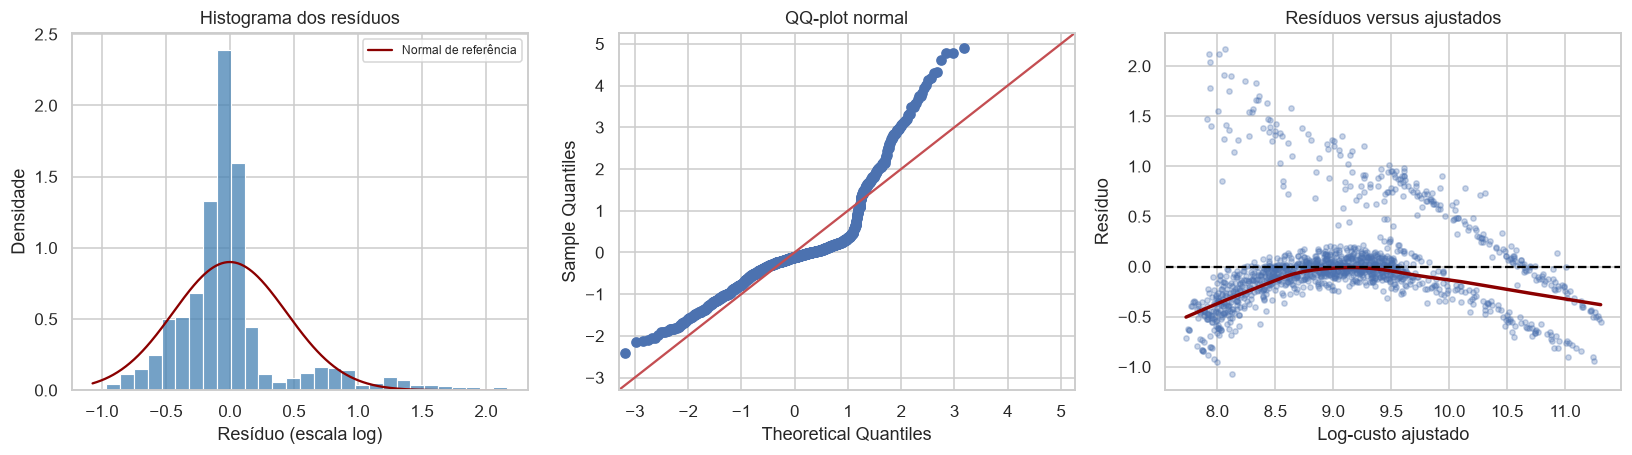

In [14]:
residuos = modelo.resid
ajustados = modelo.fittedvalues
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.3))

sns.histplot(residuos, bins=30, stat="density", ax=eixos[0], color="steelblue")
grade = np.linspace(residuos.min(), residuos.max(), 300)
eixos[0].plot(grade, stats.norm.pdf(
    grade, loc=residuos.mean(), scale=residuos.std(ddof=1)
), color="darkred", label="Normal de referência")
eixos[0].set(title="Histograma dos resíduos", xlabel="Resíduo (escala log)", ylabel="Densidade")
eixos[0].legend(fontsize=8)

sm.qqplot(residuos, fit=True, line="45", ax=eixos[1])
eixos[1].set_title("QQ-plot normal")

sns.regplot(x=ajustados, y=residuos, lowess=True, ax=eixos[2],
            scatter_kws={"alpha": .3, "s": 12}, line_kws={"color": "darkred"})
eixos[2].axhline(0, color="black", linestyle="--")
eixos[2].set(title="Resíduos versus ajustados", xlabel="Log-custo ajustado", ylabel="Resíduo")
plt.tight_layout()
plt.show()

Leitura dos gráficos. O histograma dos resíduos tem forte concentração
próxima de zero e cauda mais longa à direita, divergindo da normal de referência.
O QQ-plot apresenta desvios sistemáticos, sobretudo na cauda superior.
Em resíduos versus ajustados, a curva suavizada se afasta de zero e forma
um arco; a dispersão também varia ao longo dos valores ajustados. Portanto,
a transformação da resposta não eliminou sinais de não normalidade,
especificação inadequada e variância não constante. Os testes abaixo
complementam essas evidências visuais.

#### Testes de normalidade, variância e forma funcional
Adotamos α = 5%. O Shapiro-Wilk testa normalidade; o Breusch-Pagan,
na versão de Koenker, testa variância constante em relação às preditoras.
O teste RESET complementa a inspeção de linearidade ao avaliar termos
quadrático e cúbico dos valores ajustados. Para estabilidade numérica,
esses valores são padronizados apenas no teste auxiliar; o modelo
principal e seus coeficientes não são alterados.

A não rejeição não comprova uma premissa. Testes são complementares aos
gráficos e pressupõem condições de amostragem que a documentação não
permite verificar integralmente.

In [15]:
shapiro_w, shapiro_p = stats.shapiro(residuos)
bp_lm, bp_p, _, _ = het_breuschpagan(
    residuos, modelo.model.exog, robust=True
)

# RESET: compara o modelo original com um auxiliar contendo ajustados² e ajustados³.
u = (ajustados.to_numpy() - ajustados.mean()) / ajustados.std(ddof=0)
X_aux = np.column_stack([modelo.model.exog, u ** 2, u ** 3])
auxiliar = sm.OLS(modelo.model.endog, X_aux).fit()
reset_f, reset_p, reset_gl = auxiliar.compare_f_test(modelo)
assert int(reset_gl) == 2, "Os dois termos do RESET devem acrescentar posto."

testes = pd.DataFrame({
    "teste": ["Shapiro-Wilk", "Breusch-Pagan/Koenker (LM)", "RESET (F)"],
    "H0": ["Normalidade", "Variância constante", "Termos adicionais dispensáveis"],
    "estatistica": [shapiro_w, bp_lm, reset_f],
    "p_valor": [shapiro_p, bp_p, reset_p]
})
testes["decisao_5pct"] = np.where(
    testes["p_valor"] < .05, "Rejeitar H0", "Não rejeitar H0"
)
display(testes.style.format({"estatistica": "{:.4f}", "p_valor": "{:.3e}"}))

,teste,H0,estatistica,p_valor,decisao_5pct
0,Shapiro-Wilk,Normalidade,0.8373,6.801e-35,Rejeitar H0
1,Breusch-Pagan/Koenker (LM),Variância constante,77.0808,1.888e-13,Rejeitar H0
2,RESET (F),Termos adicionais dispensáveis,153.5659,1.021e-60,Rejeitar H0


In [16]:
display(Markdown(
    f"**Resultados dos testes.** Shapiro-Wilk: **p = {shapiro_p:.3e}**; "
    f"Breusch-Pagan/Koenker: **p = {bp_p:.3e}**; RESET: **p = {reset_p:.3e}**. "
    "Os três testes rejeitam suas hipóteses nulas a 5% nesta amostra. "
    "Há evidência contra normalidade, variância constante e a adequação "
    "da forma funcional testada. A transformação logarítmica "
    "reduziu a assimetria marginal, mas isso não implicou normalidade dos "
    "erros condicionais. A rejeição no RESET não identifica "
    "automaticamente sua causa: não linearidade e termos omitidos são "
    "possibilidades. Diante da rejeição no teste de variância, os erros "
    "padrão convencionais deixam de ser a base preferível de inferência."
))

**Resultados dos testes.** Shapiro-Wilk: **p = 6.801e-35**; Breusch-Pagan/Koenker: **p = 1.888e-13**; RESET: **p = 1.021e-60**. Os três testes rejeitam suas hipóteses nulas a 5% nesta amostra. Há evidência contra normalidade, variância constante e a adequação da forma funcional testada. A transformação logarítmica reduziu a assimetria marginal, mas isso não implicou normalidade dos erros condicionais. A rejeição no RESET não identifica automaticamente sua causa: não linearidade e termos omitidos são possibilidades. Diante da rejeição no teste de variância, os erros padrão convencionais deixam de ser a base preferível de inferência.

#### Independência e sensibilidade da inferência
Os dados são de corte transversal, sem data nem identificação de pessoa,
família ou conglomerado. A independência não pode ser comprovada com
as informações disponíveis. A sequência das linhas não é uma ordem temporal;
por isso não aplicamos um teste de autocorrelação temporal arbitrariamente.
A linha repetida reforça essa incerteza. Consideramos independência uma
hipótese de trabalho não verificada, e não uma premissa confirmada.

Como complemento diante de heterocedasticidade, calculamos erros padrão HC3.
Eles não alteram coeficientes ou R² e não corrigem dependência, forma funcional
inadequada ou seleção de variáveis. A comparação serve como sensibilidade,
sem transformar o modelo em plenamente adequado.

In [17]:
robusto = modelo.get_robustcov_results(cov_type="HC3")
ic_hc3 = robusto.conf_int()
tabela_hc3 = pd.DataFrame({
    "coeficiente": modelo.params,
    "EP_convencional": modelo.bse,
    "EP_HC3": robusto.bse,
    "p_HC3": robusto.pvalues,
    "IC95_HC3_inf": ic_hc3[:, 0],
    "IC95_HC3_sup": ic_hc3[:, 1]
})
display(tabela_hc3.style.format({
    "coeficiente": "{:.4f}", "EP_convencional": "{:.4f}", "EP_HC3": "{:.4f}",
    "p_HC3": "{:.3e}", "IC95_HC3_inf": "{:.4f}", "IC95_HC3_sup": "{:.4f}"
}))
termos_nao_sig_hc3 = [
    nome for nome, p in zip(modelo.params.index, robusto.pvalues)
    if nome != "Intercept" and p >= .05
]
display(Markdown(
    "**Sensibilidade.** A tabela HC3 mantém as estimativas e altera sua "
    "incerteza. Coeficientes não significativos a 5% por HC3: **"
    + (", ".join(termos_nao_sig_hc3) if termos_nao_sig_hc3 else "nenhum")
    + "**. Isso não autoriza nova seleção apenas para eliminar p-valores "
    "e não afasta os problemas de especificação identificados."
))

,coeficiente,EP_convencional,EP_HC3,p_HC3,IC95_HC3_inf,IC95_HC3_sup
Intercept,7.0306,0.0724,0.0705,0.000e+00,6.8923,7.1688
C(smoker)[T.Sim],1.5543,0.0303,0.0329,4.625e-287,1.4898,1.6188
C(region)[T.Noroeste],-0.0638,0.0349,0.0350,6.866e-02,-0.1325,0.0049
C(region)[T.Sudeste],-0.1572,0.0351,0.0369,2.141e-05,-0.2295,-0.0849
C(region)[T.Sudoeste],-0.1290,0.0350,0.0341,1.636e-04,-0.1959,-0.0620
C(sex)[T.Masculino],-0.0754,0.0244,0.0245,2.131e-03,-0.1235,-0.0273
age,0.0346,0.0009,0.0010,6.428e-183,0.0326,0.0366
children,0.1019,0.0101,0.0092,4.230e-27,0.0837,0.1200
bmi,0.0134,0.0021,0.0022,8.602e-10,0.0091,0.0176


**Sensibilidade.** A tabela HC3 mantém as estimativas e altera sua incerteza. Coeficientes não significativos a 5% por HC3: **C(region)[T.Noroeste]**. Isso não autoriza nova seleção apenas para eliminar p-valores e não afasta os problemas de especificação identificados.

#### Síntese: qualidade do ajuste e premissas LINE
O quadro seguinte responde diretamente às quatro premissas do enunciado.
Rejeições são evidências contra os aspectos avaliados, não provas de uma
causa específica. Um modelo com limitações pode ser útil descritivamente,
mas suas conclusões precisam refletir os diagnósticos.

In [18]:
quadro_line = pd.DataFrame({
    "premissa": [
        "L - função linear", "I - erros independentes",
        "N - normalidade dos erros", "E - variância constante"
    ],
    "avaliacao": [
        "Evidência de inadequação no RESET" if reset_p < .05 else "Não rejeitada pelo RESET; ver gráficos",
        "Não verificável com a documentação disponível",
        "Rejeitada pelo Shapiro-Wilk" if shapiro_p < .05 else "Não rejeitada pelo Shapiro-Wilk",
        "Rejeitada pelo Breusch-Pagan" if bp_p < .05 else "Não rejeitada pelo Breusch-Pagan"
    ]
})
display(quadro_line)

display(Markdown(
    f"**Conclusão sobre o ajuste.** O modelo selecionado contém "
    f"**{len(termos_selecionados)} preditoras** e explica "
    f"**{100 * modelo.rsquared:.2f}%** da variabilidade de log(charges), "
    f"com R² ajustado de **{modelo.rsquared_adj:.4f}**. "
    "Isso representa uma fração importante da variabilidade na escala "
    "analisada, mas é ajuste dentro da amostra, não validação externa. "
    "Os resultados de LINE no quadro impedem apresentar o ajuste "
    "como confirmação de todas as premissas."
))

,premissa,avaliacao
0,L - função linear,Evidência de inadequação no RESET
1,I - erros independentes,Não verificável com a documentação disponível
2,N - normalidade dos erros,Rejeitada pelo Shapiro-Wilk
3,E - variância constante,Rejeitada pelo Breusch-Pagan


**Conclusão sobre o ajuste.** O modelo selecionado contém **6 preditoras** e explica **76.79%** da variabilidade de log(charges), com R² ajustado de **0.7666**. Isso representa uma fração importante da variabilidade na escala analisada, mas é ajuste dentro da amostra, não validação externa. Os resultados de LINE no quadro impedem apresentar o ajuste como confirmação de todas as premissas.

Conclusão substantiva e limitações. O modelo permite quantificar associações
ajustadas entre características individuais e custos; os contrastes de
tabagismo devem ser interpretados em conjunto com idade, IMC e demais termos
selecionados. Os gráficos e testes indicam que normalidade, forma funcional e
homogeneidade das variâncias não são sustentadas nesta especificação;
a independência permanece não verificável. Portanto, o modelo é uma descrição
inicial com limitações importantes, e não uma especificação plenamente validada.
A ausência de informações sobre comorbidades, tipo de plano,
estrutura familiar e processo amostral limita explicações e generalizações.

O logaritmo é linear na resposta transformada, mas não garante uma especificação
adequada da média condicional. Não foram acrescentadas interações ou polinômios
apenas para obter p-valores favoráveis. Uma continuação justificável seria
investigar curvatura da idade e interação entre IMC e tabagismo, mantendo
a hierarquia dos termos e reavaliando os resíduos. A inferência HC3 é uma
sensibilidade à heterocedasticidade, não uma solução para todas as limitações.

A seleção na própria amostra e a escolha exploratória da transformação não
estão incorporadas nos intervalos usuais. O estudo não identifica efeitos
causais, não estima riscos clínicos e não garante previsões para outras
populações. A análise cumpre o propósito de aplicar e avaliar regressão linear
múltipla, incluindo o reconhecimento de suas limitações.

In [19]:
print("Versões utilizadas na execução:")
print({
    "Python": platform.python_version(), "pandas": pd.__version__,
    "numpy": np.__version__, "scipy": scipy.__version__,
    "statsmodels": statsmodels.__version__, "seaborn": sns.__version__
})

Versões utilizadas na execução:
{'Python': '3.12.1', 'pandas': '3.0.2', 'numpy': '2.4.4', 'scipy': '1.18.1', 'statsmodels': '0.15.0', 'seaborn': '0.13.2'}
